# 04 · Flood Records and Labels

**Project:** Spatio-Temporal Prediction of Pluvial and Coastal Flood Risk in Lagos State, Nigeria
**Notebook:** 04 of the series · **Author:** Utibe Bassey

## Purpose

A model learns from examples, so it needs to know **which LGA-months had a flood and which did not**. No clean public dataset of Lagos floods exists, so this notebook builds one from several sources and turns it into a table of labels.

This is the **riskiest step of the whole project**. The result decides how reliable the model can be, so the notebook ends with a feasibility check.

## Sources

| Source | What it gives | How it enters |
| --- | --- | --- |
| **DFO Global Active Archive** (Dartmouth Flood Observatory) | Large flood events with outlines, built from news, government and satellite sources | Loaded automatically from a public mirror (covers events up to about 2022) |
| **DFO Excel file** (optional) | Later events, but only a centre point per event | Add `dfo_archive.xlsx` to `data/raw/flood_events/` |
| **Your event log** | Floods reported by news, LASEMA, NEMA, EM-DAT or papers, one row per event | You fill in `flood_events_log.csv` |

## The labelling rule

> An **LGA-month is labelled 1 (flood)** if at least one credible source documents a flood affecting that LGA in that month. Otherwise it is labelled **0**.

**Important:** a 0 means "**no documented flood**", not "no flood". Many small floods are never recorded. This is a limitation to state in the report.

## Two label tables are produced

1. **LGA-month labels** (3,840 rows): used for the main model. Built only from events where we know which LGAs were affected.
2. **State-month labels** (192 rows): "was there any documented flood in Lagos State this month?" This includes wide-area events whose LGAs are unknown. It is the **fallback** target if LGA-level events turn out to be too few.

## Inputs and outputs

| | File |
| --- | --- |
| **Input** | `data/clean/lagos_lgas.gpkg` (notebook 01) |
| **Input** | `data/raw/flood_events/flood_events_log.csv` (you create the content) |
| **Output** | `data/clean/flood_events_combined.csv` |
| **Output** | `data/clean/flood_labels_lga_month.csv` |
| **Output** | `data/clean/flood_labels_state_month.csv` |

## 1. Setup

In [1]:
from pathlib import Path
import re

import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

### Settings

Everything you might want to change is in this cell.

In [2]:
START_MONTH = "2010-01"        # first month of the study period
END_MONTH = "2025-12"          # last month of the study period

# DFO outlines are often drawn around whole river basins. An event that touches more than this
# many LGAs is treated as a "regional" event: it counts for the state-level label only.
DFO_MAX_LGAS = 10

# Events from your log with a severity below this are ignored (1 = include everything, 2 = only significant floods)
MIN_SEVERITY = 1

LGA_PATH = Path("../data/clean/lagos_lgas.gpkg")
EVENT_DIR = Path("../data/raw/flood_events")
LOG_PATH = EVENT_DIR / "flood_events_log.csv"        # YOUR event log
DFO_XLSX = EVENT_DIR / "dfo_archive.xlsx"            # optional DFO Excel download

OUT_EVENTS = Path("../data/clean/flood_events_combined.csv")
OUT_LGA = Path("../data/clean/flood_labels_lga_month.csv")
OUT_STATE = Path("../data/clean/flood_labels_state_month.csv")

EVENT_DIR.mkdir(parents=True, exist_ok=True)
OUT_LGA.parent.mkdir(parents=True, exist_ok=True)

In [3]:
lagos = gpd.read_file(LGA_PATH)
LGA_NAMES = lagos["lga"].tolist()
print("LGAs loaded:", len(LGA_NAMES))

# Helper: turn any spelling of an LGA name into the official spelling used in our data
def norm(text):
    return re.sub(r"[^a-z]", "", str(text).lower())

LGA_BY_KEY = {norm(name): name for name in LGA_NAMES}
LGA_BY_KEY.update({                                   # common alternative spellings
    "lagosmainland": "Mainland",
    "ifakoijaiye": "Ifako/Ijaye",
    "somolu": "Shomolu",
    "ajeromi": "Ajeromi/Ifelodun",
    "ifelodun": "Ajeromi/Ifelodun",
    "amuwo": "Amuwo Odofin",
    "oshodi": "Oshodi/Isolo",
    "ibeju": "Ibeju-Lekki",
})

study_months = pd.period_range(START_MONTH, END_MONTH, freq="M")
print("Months in study period:", len(study_months))

LGAs loaded: 20
Months in study period: 192


## 2. Source A: DFO archive (public mirror)

The Dartmouth Flood Observatory archive is free for research and education. Its own website may not load from every connection, so we read a public copy of the same archive that is hosted on ArcGIS. **The copy was last updated in September 2022**, so it will not contain 2023-2025 events.

The cell asks the service for Nigerian events only.

In [4]:
DFO_URL = ("https://services1.arcgis.com/AXaYBvnJsB5Q7sDF/ArcGIS/rest/services/"
           "Global_Archive_of_large_flood_events/FeatureServer/0/query")

params = {
    "where": "UPPER(COUNTRY) LIKE '%NIGERIA%' OR UPPER(OTHERCOUNT) LIKE '%NIGERIA%'",
    "outFields": "*",
    "f": "geojson",
    "resultRecordCount": 2000,
}

dfo_raw = gpd.GeoDataFrame()   # stays empty if the download fails, and the notebook carries on

try:
    resp = requests.get(DFO_URL, params=params, timeout=60)
    resp.raise_for_status()
    features = resp.json().get("features", [])
    dfo_raw = gpd.GeoDataFrame.from_features(features, crs="EPSG:4326")

    # Dates arrive as milliseconds since 1970, so convert them
    for col in ["BEGAN", "ENDED"]:
        dfo_raw[col] = pd.to_datetime(dfo_raw[col], unit="ms", errors="coerce")

    print("Nigeria events (all years):", len(dfo_raw))
    print("Events since 2010:", int((dfo_raw["BEGAN"].dt.year >= 2010).sum()))
    print("Latest event date:", dfo_raw["BEGAN"].max().date())
except Exception as err:
    print("DFO download failed:", str(err)[:200])
    print("The notebook will continue without it. Send me the error above if you want help.")

Nigeria events (all years): 69
Events since 2010: 22
Latest event date: 2021-08-10


### Which of these events touch Lagos?

For each event we find the LGAs its outline overlaps. **Look at the `n_lgas` column:** if an outline touches most of the 20 LGAs, it describes a regional flood and cannot tell us which LGA flooded. Those events are marked `regional` and kept for the state-level label only.

In [5]:
EVENT_COLUMNS = ["event_id", "source_type", "source_name", "source_url", "date_start", "date_end",
                 "place_text", "lgas", "regional", "severity", "notes"]

def empty_events():
    return pd.DataFrame(columns=EVENT_COLUMNS)

dfo_events = empty_events()

if len(dfo_raw) > 0:
    dfo_use = dfo_raw.dropna(subset=["ID", "BEGAN"]).copy()
    dfo_use["ENDED"] = dfo_use["ENDED"].fillna(dfo_use["BEGAN"])

    # keep events that overlap the study period
    period_start = study_months[0].to_timestamp()
    period_end = study_months[-1].to_timestamp(how="end")
    dfo_use = dfo_use[(dfo_use["ENDED"] >= period_start) & (dfo_use["BEGAN"] <= period_end)]

    # which LGAs does each event outline overlap?
    hits = gpd.sjoin(dfo_use, lagos[["lga", "geometry"]], predicate="intersects", how="inner")

    if len(hits) > 0:
        grouped = hits.groupby("ID").agg(
            began=("BEGAN", "first"), ended=("ENDED", "first"),
            cause=("MAINCAUSE", "first"), severity_class=("SEVERITY", "first"),
            dead=("DEAD", "first"), displaced=("DISPLACED", "first"),
            lgas=("lga", lambda s: sorted(set(s))),
        ).reset_index()
        grouped["n_lgas"] = grouped["lgas"].apply(len)

        dfo_events = pd.DataFrame({
            "event_id": "DFO-" + grouped["ID"].astype(int).astype(str),
            "source_type": "DFO",
            "source_name": "Dartmouth Flood Observatory",
            "source_url": "https://floodobservatory.colorado.edu/Archives/index.html",
            "date_start": grouped["began"],
            "date_end": grouped["ended"],
            "place_text": "DFO outline",
            "lgas": grouped["lgas"],
            "regional": grouped["n_lgas"] > DFO_MAX_LGAS,
            "severity": float("nan"),
            "notes": ("cause: " + grouped["cause"].fillna("?").astype(str)
                      + "; DFO class: " + grouped["severity_class"].astype(str)
                      + "; dead: " + grouped["dead"].astype(str)
                      + "; displaced: " + grouped["displaced"].astype(str)),
        })
        display_cols = grouped[["ID", "began", "ended", "cause", "n_lgas", "dead", "displaced"]]
        print("DFO events touching Lagos:", len(dfo_events))
        print("Of these, regional (touch more than", DFO_MAX_LGAS, "LGAs):", int(dfo_events["regional"].sum()))
        display(display_cols.sort_values("began"))
    else:
        print("No DFO events overlap Lagos in the study period.")
else:
    print("No DFO data loaded.")

DFO events touching Lagos: 1
Of these, regional (touch more than 10 LGAs): 1


,ID,began,ended,cause,n_lgas,dead,displaced
0,4649,2018-07-13,2018-07-17,Torrential Rain,19,48,0


## 3. Source B: DFO Excel file (optional)

If you can download the full DFO archive as Excel, save it as `data/raw/flood_events/dfo_archive.xlsx`. It runs to the present, so it can add **2023-2025** events. It holds only a centre point per event, so these events count for the **state-level** label only (they cannot say which LGA flooded).

If the file is not there, this cell is skipped.

In [6]:
dfo_xlsx_events = empty_events()

if DFO_XLSX.exists():
    x = pd.read_excel(DFO_XLSX)
    x.columns = [str(c).strip().lower() for c in x.columns]
    print("Columns found:", x.columns.tolist())

    needed = {"id", "country", "began", "ended", "long", "lat"}
    if needed.issubset(x.columns):
        x = x[x["country"].astype(str).str.upper().str.contains("NIGERIA", na=False)].copy()
        x["began"] = pd.to_datetime(x["began"], errors="coerce")
        x["ended"] = pd.to_datetime(x["ended"], errors="coerce").fillna(x["began"])
        x = x.dropna(subset=["id", "began", "long", "lat"])

        # keep events whose centre point lies in or near Lagos State (about 5 km tolerance)
        lagos_area = lagos.geometry.union_all().buffer(0.05)
        pts = gpd.GeoSeries(gpd.points_from_xy(x["long"], x["lat"]), index=x.index, crs="EPSG:4326")
        x = x[pts.within(lagos_area)]

        # skip events already loaded from the mirror
        known = set(dfo_events["event_id"])
        x = x[~("DFO-" + x["id"].astype(int).astype(str)).isin(known)]

        dfo_xlsx_events = pd.DataFrame({
            "event_id": "DFO-" + x["id"].astype(int).astype(str),
            "source_type": "DFO",
            "source_name": "Dartmouth Flood Observatory (Excel)",
            "source_url": "https://floodobservatory.colorado.edu/Archives/index.html",
            "date_start": x["began"], "date_end": x["ended"],
            "place_text": "DFO centre point",
            "lgas": [[] for _ in range(len(x))],
            "regional": True,
            "severity": float("nan"),
            "notes": "centre point only, used for state-level label",
        })
        print("Extra DFO events near Lagos from Excel:", len(dfo_xlsx_events))
    else:
        print("Expected columns missing:", needed - set(x.columns), "- send me the column list above.")
else:
    print("No DFO Excel file found. Skipping.")

No DFO Excel file found. Skipping.


## 4. Source C: your event log (the main source)

This is the most important source. Each row is **one flood event** that a credible source reports in Lagos. The more events you record, the better the model can be.

### Columns of `flood_events_log.csv`

| Column | What to enter | Example of the format |
| --- | --- | --- |
| `event_id` | Optional short ID | `N001` |
| `date_start` | First day of the flood, `YYYY-MM-DD` | `2022-07-11` |
| `date_end` | Last day (leave blank for a one-day event) | `2022-07-12` |
| `place_text` | The place exactly as the report names it | `Ajegunle` |
| `lga` | Official LGA name. Use `;` for several. Use `ALL` for a statewide flood. Leave blank to let the notebook guess from `place_text` | `Ajeromi/Ifelodun` |
| `source_type` | `news`, `LASEMA`, `NEMA`, `EM-DAT`, `paper` or `other` | `news` |
| `source_name` | Name of the outlet or document | `Punch` |
| `source_url` | Link to the report | `https://...` |
| `severity` | 1 = street or road flooding. 2 = homes or businesses flooded, or roads impassable. 3 = deaths, large displacement or emergency response | `2` |
| `notes` | Anything useful | `Heavy rain overnight` |

*The example values only show the format. Do not copy them into your log.*

### Rules for good records

- Only record events with **a date and a place** from a **credible, published** source, and always keep the link.
- One event can have several rows if it hit several LGAs on the same day, or you can list the LGAs with `;`.
- Do not guess dates. If a report gives only a month, use the 1st of that month for `date_start`, and write "month only" in `notes`.
- **Where to look:** news sites (Punch, Vanguard, Guardian Nigeria, Premium Times, Channels, TheCable), LASEMA and NEMA announcements, and EM-DAT (free registration) for the flood events it lists for Lagos. Search with words like "flood Lagos July 2022". Start with the rainy months, May to October.
- **Target:** at least 100 events across 2010-2025, and more if you can.

The next cell creates an empty template if the file does not exist yet.

In [7]:
LOG_COLUMNS = ["event_id", "date_start", "date_end", "place_text", "lga",
               "source_type", "source_name", "source_url", "severity", "notes"]

if not LOG_PATH.exists():
    pd.DataFrame(columns=LOG_COLUMNS).to_csv(LOG_PATH, index=False)
    print("Created an empty template:", LOG_PATH.resolve())
    print("Open it in Excel, add your events, save as CSV, then rerun from this cell.")
else:
    print("Event log found:", LOG_PATH.resolve())

Event log found: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\raw\flood_events\flood_events_log.csv


### Place-to-LGA lookup

Reports usually name a **neighbourhood** ("Ajegunle", "Ketu"), not an LGA. If you leave `lga` blank, the notebook uses this lookup to fill it in.

> **This is a starter list. Please check each entry against an official source** (for example the Lagos State government's list of LGAs and LCDAs) and **add more places as you meet them**. Some names, such as "Lekki" and "Ikorodu", are broad, so when a report is specific about the location, enter the LGA yourself.

In [8]:
PLACE_TO_LGA = {
    "Eti-Osa": [
        "lekki", "victoria island", "ikoyi", "ajah", "ikota", "oniru", "banana island",
        "ikate", "osapa london", "sangotedo", "ilasan", "elegushi", "eti-osa", "eti osa",
        "agungi", "jakande", "chevron", "ado", "badore", "abRAHAM adesanya", "obadeyi"
    ],
    "Ibeju-Lekki": ["ibeju", "ibeju-lekki", "eleko", "akodo", "bogije", "lakowe", "awoyaya", " eputu"],
    "Kosofe": [
        "ketu", "mile 12", "ojota", "gbagada", "ogudu", "magodo", "alapere", "agboyi",
        "ikosi", "kosofe", "isheri", "oworo", "iyana-oworo", "iyana oworo", "mendel", "anthony"
    ],
    "Ikeja": [
        "ikeja", "alausa", "oregun", "allen avenue", "opebi", "agidingbi", "ogba",
        "maryland", "omole", "computer village", "gra ikeja"
    ],
    "Agege": ["agege", "orile agege", "dopemu", "oko oba", "oko-oba", "pen cinema", "abattoir", "sango-agege"],
    "Alimosho": [
        "alimosho", "ikotun", "egbeda", "idimu", "igando", "iyana ipaja", "ipaja", "akowonjo",
        "abule egba", "abule-egba", "ayobo", "command", "agbado", "baruwa", "isheri olofin", "shasha"
    ],
    "Ifako/Ijaye": ["ifako", "ijaiye", "ifako-ijaiye", "ifako/ijaye", "ojokoro", "agbado ijaye", "fagba", "iju", "akute"],
    "Oshodi/Isolo": ["oshodi", "isolo", "ejigbo", "okota", "mafoluku", "ajao estate", "ago palace", "oke-afa", "oke afa", "shogunle"],
    "Mushin": ["mushin", "idi-oro", "ilupeju", "papa ajao", "olosa", "ire akari", "idi araba", "itire-ikate"],
    "Shomolu": ["shomolu", "somolu", "bariga", "pedro", "onipanu", "palmgrove", "fadeyi", "gbagada phase 1"],
    "Surulere": [
        "surulere", "iponri", "aguda", "itire", "ijesha", "iganmu", "orile iganmu", "orile",
        "ojuelegba", "lawanson", "bode thomas", "adeniran ogunsanya", "ikate surulere", " Kilo"
    ],
    "Mainland": [
        "yaba", "ebute metta", "ebute-metta", "oyingbo", "makoko", "iddo", "otto",
        "alagomeji", "akoka", "ijora", "sabo", "costain", "mainland", "lagos mainland"
    ],
    "Lagos Island": [
        "lagos island", "marina", "obalende", "idumota", "balogun", "onikan",
        "isale eko", "adeniji adele", "cms", "broad street", "tafawa balewa"
    ],
    "Apapa": ["apapa", "tin can", "tincan", "kirikiri", "olodi apapa", "marine beach", "wharf"],
    "Ajeromi/Ifelodun": ["ajegunle", "ajeromi", "ifelodun", "ajeromi/ifelodun", "boundary", "orile-ajeromi", "tolu", "amkoko"],
    "Amuwo Odofin": ["festac", "amuwo", "amuwo odofin", "mile 2", "satellite town", "agboju", "abule ado", "trade fair", "kirikiri town"],
    "Ojo": ["ojo", "okokomaiko", "iba", "ijanikin", "alaba", "ajangbadi", "iyana iba", "lasu", "otto awori"],
    "Badagry": ["badagry", "ajara", "ibereko", "mowo", "aradagun", "morogbo", "topo", "seme"],
    "Ikorodu": ["ikorodu", "ijede", "imota", "igbogbo", "majidun", "ibeshe", "agric", "owutu", "isawo", "baiyeku", "pakodo"],
    "Epe": ["epe", "ejirin", "eredo", "agbowa", "itoikin", "poka", "odoragunsin"],
}

# Every LGA name in the lookup must exist in our map
unknown = [k for k in PLACE_TO_LGA if k not in LGA_NAMES]
assert not unknown, f"Lookup uses LGA names that are not in the map: {unknown}"

# Word-boundary patterns, so "ojo" does not match "ojota" or "ojodu"
PLACE_PATTERNS = [
    (re.compile(r"\b" + re.escape(place.strip().lower()) + r"\b"), lga)
    for lga, places in PLACE_TO_LGA.items() for place in places
]

def lgas_from_place(text):
    text = str(text).lower()
    return sorted({lga for pattern, lga in PLACE_PATTERNS if pattern.search(text)})

### Read and check the log

Each row is checked, and anything that cannot be used is **listed with the reason**, so you can fix the log and rerun.

In [9]:
log_events = empty_events()
problems = []

log = pd.read_csv(LOG_PATH, dtype=str).dropna(how="all")
print("Rows in your log:", len(log))

rows = []
for i, r in log.iterrows():
    row_no = i + 2   # the row number you see in Excel (row 1 is the header)

    start = pd.to_datetime(r.get("date_start"), errors="coerce")
    if pd.isna(start):
        problems.append((row_no, "date_start missing or not in YYYY-MM-DD format"))
        continue
    end = pd.to_datetime(r.get("date_end"), errors="coerce")
    if pd.isna(end) or end < start:
        end = start

    severity = pd.to_numeric(r.get("severity"), errors="coerce")
    if pd.notna(severity) and severity < MIN_SEVERITY:
        continue   # below the severity threshold set in the settings

    # work out which LGAs this event affected
    lga_text = str(r.get("lga", "")).strip()
    regional = False
    lgas = []
    if lga_text.upper() == "ALL":
        regional = True
    elif lga_text and lga_text.lower() != "nan":
        for part in re.split(r"[;,]", lga_text):
            key = norm(part)
            if not key:
                continue
            if key in LGA_BY_KEY:
                lgas.append(LGA_BY_KEY[key])
            else:
                problems.append((row_no, f"LGA '{part.strip()}' is not one of the 20 official names"))
        lgas = sorted(set(lgas))
    else:
        lgas = lgas_from_place(r.get("place_text", ""))   # guess from the place name
        if not lgas:
            problems.append((row_no, f"could not match place '{r.get('place_text')}' to an LGA: fill the lga column"))
            continue

    if not regional and not lgas:
        continue   # a problem was already recorded for this row

    rows.append({
        "event_id": r.get("event_id") if pd.notna(r.get("event_id")) else f"LOG-{row_no}",
        "source_type": r.get("source_type"), "source_name": r.get("source_name"),
        "source_url": r.get("source_url"),
        "date_start": start, "date_end": end,
        "place_text": r.get("place_text"), "lgas": lgas, "regional": regional,
        "severity": severity, "notes": r.get("notes"),
    })

log_events = pd.DataFrame(rows, columns=EVENT_COLUMNS) if rows else empty_events()

print("Usable events from your log:", len(log_events))
if problems:
    print("\nRows that need fixing:")
    for row_no, why in problems:
        print(f"  row {row_no}: {why}")
else:
    print("No problems found.")

# Warn about very long events (every month in the range becomes a flood month)
if len(log_events) > 0:
    long_ev = log_events[(log_events["date_end"] - log_events["date_start"]).dt.days > 92]
    if len(long_ev) > 0:
        print("\nEvents longer than 3 months (check the dates):", long_ev["event_id"].tolist())

Rows in your log: 75
Usable events from your log: 75
No problems found.


## 5. Combine all sources into one event table

In [10]:
parts = [p for p in [dfo_events, dfo_xlsx_events, log_events] if len(p) > 0]
events = pd.concat(parts, ignore_index=True) if parts else empty_events()

events["date_start"] = pd.to_datetime(events["date_start"])
events["date_end"] = pd.to_datetime(events["date_end"])

# Keep only events that overlap the study period
p_start = study_months[0].to_timestamp()
p_end = study_months[-1].to_timestamp(how="end")
events = events[(events["date_end"] >= p_start) & (events["date_start"] <= p_end)].reset_index(drop=True)

print("Total events:", len(events))
print("  with known LGAs (used for LGA-level labels):", int((~events["regional"]).sum()))
print("  regional / unknown LGA (state-level label only):", int(events["regional"].sum()))
print()
print(events.groupby("source_type").size().rename("events").to_frame())

Total events: 76
  with known LGAs (used for LGA-level labels): 75
  regional / unknown LGA (state-level label only): 1

             events
source_type        
DFO               1
EM-DAT            3
LASEMA           14
NEMA             10
NIHSA             6
news             42


In [11]:
# Save the combined table (lists of LGAs become text separated by semicolons)
to_save = events.copy()
to_save["lgas"] = to_save["lgas"].apply(lambda v: "; ".join(v))
to_save.to_csv(OUT_EVENTS, index=False)
print("Saved:", OUT_EVENTS.resolve())

Saved: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\clean\flood_events_combined.csv


## 6. Build the label tables

**LGA-month table:** one row for every LGA and every month (20 x 192 = 3,840 rows). An event marks every month between its start and end dates as a flood month for each LGA it affected.

**State-month table:** one row per month, marked 1 if **any** event (including regional ones) happened in Lagos State that month.

In [12]:
# ---- LGA-month labels (events with known LGAs only) ----
positive_rows = []
for _, ev in events[~events["regional"]].iterrows():
    for m in pd.period_range(ev["date_start"].to_period("M"), ev["date_end"].to_period("M"), freq="M"):
        if m < study_months[0] or m > study_months[-1]:
            continue
        for lga in ev["lgas"]:
            positive_rows.append({"lga": lga, "month": m.to_timestamp(), "event_id": ev["event_id"],
                                  "severity": ev["severity"], "source_type": ev["source_type"]})

positives = pd.DataFrame(positive_rows, columns=["lga", "month", "event_id", "severity", "source_type"])

if len(positives) > 0:
    summary = positives.groupby(["lga", "month"]).agg(
        n_events=("event_id", "nunique"),
        max_severity=("severity", "max"),
        sources=("source_type", lambda s: ", ".join(sorted(set(s)))),
    ).reset_index()
else:
    summary = pd.DataFrame(columns=["lga", "month", "n_events", "max_severity", "sources"])

# Full grid: every LGA in every month
grid = pd.MultiIndex.from_product(
    [LGA_NAMES, [m.to_timestamp() for m in study_months]], names=["lga", "month"]
).to_frame(index=False)

labels = grid.merge(summary, on=["lga", "month"], how="left")
labels["n_events"] = pd.to_numeric(labels["n_events"], errors="coerce").fillna(0).astype(int)
labels["flood"] = (labels["n_events"] > 0).astype(int)
labels["year"] = labels["month"].dt.year
labels["month_num"] = labels["month"].dt.month
labels = labels[["lga", "month", "year", "month_num", "flood", "n_events", "max_severity", "sources"]]

print("LGA-month rows:", len(labels), "| expected:", len(LGA_NAMES) * len(study_months))
print("Flood months (label = 1):", int(labels["flood"].sum()))
print("Share of LGA-months labelled flood:", round(labels["flood"].mean() * 100, 2), "%")

LGA-month rows: 3840 | expected: 3840
Flood months (label = 1): 423
Share of LGA-months labelled flood: 11.02 %


In [13]:
# ---- State-month labels (any documented event, including regional ones) ----
state_rows = []
for _, ev in events.iterrows():
    for m in pd.period_range(ev["date_start"].to_period("M"), ev["date_end"].to_period("M"), freq="M"):
        if study_months[0] <= m <= study_months[-1]:
            state_rows.append({"month": m.to_timestamp(), "event_id": ev["event_id"]})

state_events = pd.DataFrame(state_rows, columns=["month", "event_id"])
state = pd.DataFrame({"month": [m.to_timestamp() for m in study_months]})
counts = state_events.groupby("month")["event_id"].nunique().rename("n_events").reset_index()
state = state.merge(counts, on="month", how="left")
state["n_events"] = pd.to_numeric(state["n_events"], errors="coerce").fillna(0).astype(int)
state["flood_any_lagos"] = (state["n_events"] > 0).astype(int)
state["year"] = state["month"].dt.year
state["month_num"] = state["month"].dt.month

print("State-month rows:", len(state), "| expected:", len(study_months))
print("Months with any documented flood in Lagos:", int(state["flood_any_lagos"].sum()))

State-month rows: 192 | expected: 192
Months with any documented flood in Lagos: 65


In [14]:
# Checks, then save
assert len(labels) == len(LGA_NAMES) * len(study_months)
assert labels.duplicated(["lga", "month"]).sum() == 0
assert set(labels["flood"].unique()) <= {0, 1}
assert len(state) == len(study_months)

labels.to_csv(OUT_LGA, index=False)
state.to_csv(OUT_STATE, index=False)
print("Saved:", OUT_LGA.resolve())
print("Saved:", OUT_STATE.resolve())

Saved: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\clean\flood_labels_lga_month.csv


Saved: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\clean\flood_labels_state_month.csv


## 7. Feasibility check: do we have enough floods to model?

Models need enough positive examples to learn from. A rough guide for this project:

| Flood LGA-months (label = 1) | Verdict | What to do |
| --- | --- | --- |
| Fewer than 50 | **Too few** | Keep collecting events. Discuss the state-level fallback with your supervisor |
| 50 to 149 | **Borderline** | Model with care: simple models, and honest reporting of uncertainty |
| 150 or more | **Good** | Go ahead with the LGA-level model |

These are practical guidelines, not strict statistical rules.

In [15]:
n_pos = int(labels["flood"].sum())
n_state_pos = int(state["flood_any_lagos"].sum())

if n_pos < 50:
    verdict = "TOO FEW: keep collecting events, or discuss the state-level fallback with your supervisor"
elif n_pos < 150:
    verdict = "BORDERLINE: possible, but use simple models and report uncertainty honestly"
else:
    verdict = "GOOD: enough flood examples for LGA-level modelling"

print(f"Flood LGA-months (label = 1): {n_pos} of {len(labels)} ({n_pos / len(labels) * 100:.1f}%)")
print(f"Months with any documented flood in Lagos State: {n_state_pos} of {len(state)}")
print("Verdict:", verdict)

Flood LGA-months (label = 1): 423 of 3840 (11.0%)
Months with any documented flood in Lagos State: 65 of 192
Verdict: GOOD: enough flood examples for LGA-level modelling


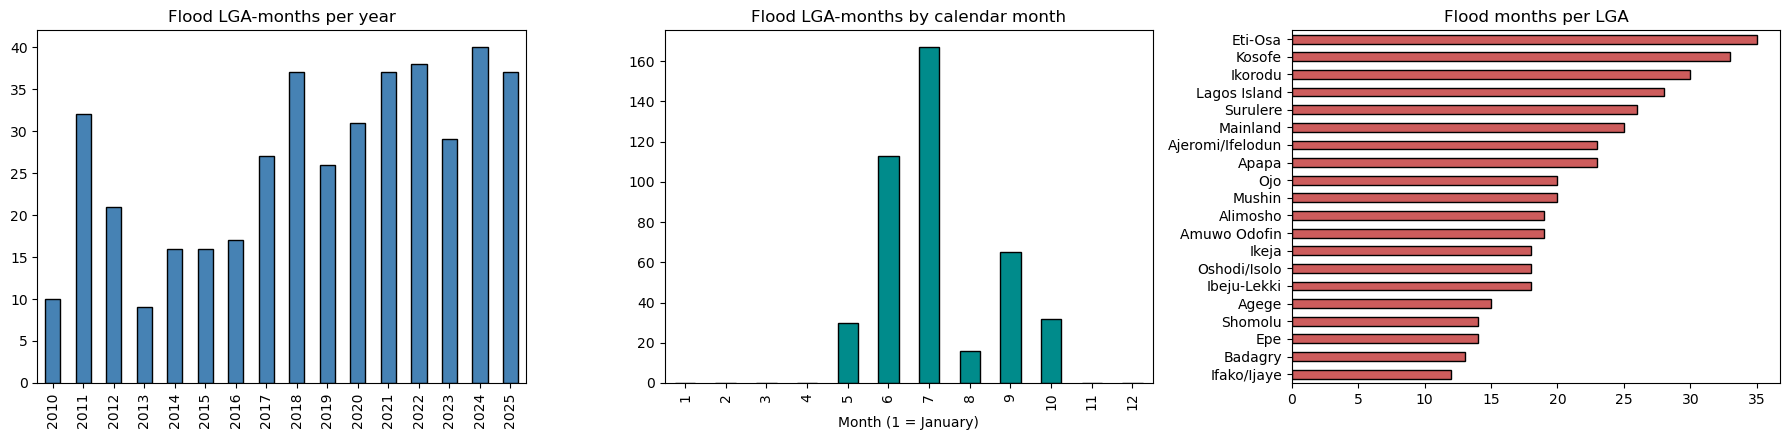

In [16]:
# Where are the floods in time and space?
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

by_year = labels.groupby("year")["flood"].sum().reindex(range(study_months[0].year, study_months[-1].year + 1), fill_value=0)
by_year.plot.bar(ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("Flood LGA-months per year")
axes[0].set_xlabel("")

by_month = labels.groupby("month_num")["flood"].sum().reindex(range(1, 13), fill_value=0)
by_month.plot.bar(ax=axes[1], color="darkcyan", edgecolor="black")
axes[1].set_title("Flood LGA-months by calendar month")
axes[1].set_xlabel("Month (1 = January)")

by_lga = labels.groupby("lga")["flood"].sum().sort_values()
by_lga.plot.barh(ax=axes[2], color="indianred", edgecolor="black")
axes[2].set_title("Flood months per LGA")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

**How to read these charts**

- **By year:** a few years with many floods and many years with none usually means **uneven reporting**, not uneven weather. If one year has all the events, look for gaps in the years with none.
- **By calendar month:** floods should peak around the rainy months (May to July, and September to October). If they do not, check your dates.
- **By LGA:** a few LGAs with many floods and the rest with none usually means **reports focus on well-known areas**, such as Lekki and Ikeja. This reporting bias is a limitation to discuss in the report.

In [17]:
# Which sources contribute most?
if len(events) > 0:
    print(events.groupby(["source_type", "regional"]).size().rename("events").to_frame())

# Years with no documented flood at all: possible gaps in the records
all_years = set(range(study_months[0].year, study_months[-1].year + 1))
empty_years = sorted(all_years - set(labels.loc[labels["flood"] == 1, "year"]))
print("\nYears with no flood in the LGA-level labels:", empty_years if empty_years else "none")

                      events
source_type regional        
DFO         True           1
EM-DAT      False          3
LASEMA      False         14
NEMA        False         10
NIHSA       False          6
news        False         42

Years with no flood in the LGA-level labels: none


## Summary

- Loaded DFO flood events (public mirror, up to about 2022) and kept those that touch Lagos
- Read your event log, matched places to LGAs, and listed every row that needed fixing
- Built **LGA-month flood labels** (3,840 rows) and a **state-month fallback** (192 rows)
- Ran a feasibility check on the number of flood examples

### Limitations to note in the report

- **Label = 1 means a documented flood.** Label = 0 means *no documented flood*, which can include floods nobody wrote about
- **Reporting bias:** well-known and wealthy areas are reported more often, and recent years are better covered than early ones
- **DFO events are "large" floods only**, and their outlines are coarse
- **Month resolution:** an event is placed in every month it touched, so a one-day flood marks the entire month

### Next

If the verdict is **borderline or too few**, keep adding events to the log and rerun this notebook. Each added event improves the project.

When you are happy with the labels, go to **`05_population_landcover.ipynb`**: population and built-up land for each LGA.